# Yaya Touré at Manchester City, 2010–2018

Official Premier League (Opta) stats for every Premier League midfielder from 2010/11 to 2017/18:
1,629 player-seasons, 617 of them with 1,800+ minutes. Collected from premierleague.com and saved in
`data/external/pl_midfielders_2010-2018.csv`.

"Midfielder" means listed as a midfielder in his club's squad that season, so it includes wide players such as
Hazard, Bale and Mahrez.

In [1]:
from pathlib import Path
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad"
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2013 -> '2013/14'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2017/18 (official Opta stats)."""
    d = pd.read_csv(EXT / "pl_midfielders_2010-2018.csv")
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["passes90"] = p90(d.totalPasses)
    d["pass_pct"] = 1 - d.totalUnsuccessfulPassesExclCrossesAndCorners / d.totalPasses
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
YAYA = "Yaya Touré"

In [2]:
D = load_opta()
M = load_opta(min_minutes=1800)            # regulars: 1,800+ league minutes
for c in DIMS + ["passes90"]:
    M["p_" + c] = M.groupby("season")[c].rank(pct=True)
Y = D[D.name == YAYA].sort_values("season")
Y[["season", "appearances", "timePlayed", "goals", "penaltyGoals", "goalAssists", "expectedGoals", "totalPasses", "pass_pct"]].round(2)

,season,appearances,timePlayed,goals,penaltyGoals,goalAssists,expectedGoals,totalPasses,pass_pct
73,2010,35,2976,8,0,4,0.00,1834,0.85
263,2011,32,2651,6,0,6,0.00,2419,0.90
451,2012,32,2829,7,0,5,4.33,2525,0.89
640,2013,35,2927,20,6,9,10.06,2502,0.90
842,2014,29,2355,10,2,1,6.80,2412,0.89
1030,2015,32,2331,6,1,5,6.30,1838,0.86
1242,2016,25,1947,5,2,0,3.48,1799,0.90
1448,2017,10,228,0,0,2,0.37,416,0.94


## 1. Eight seasons in numbers

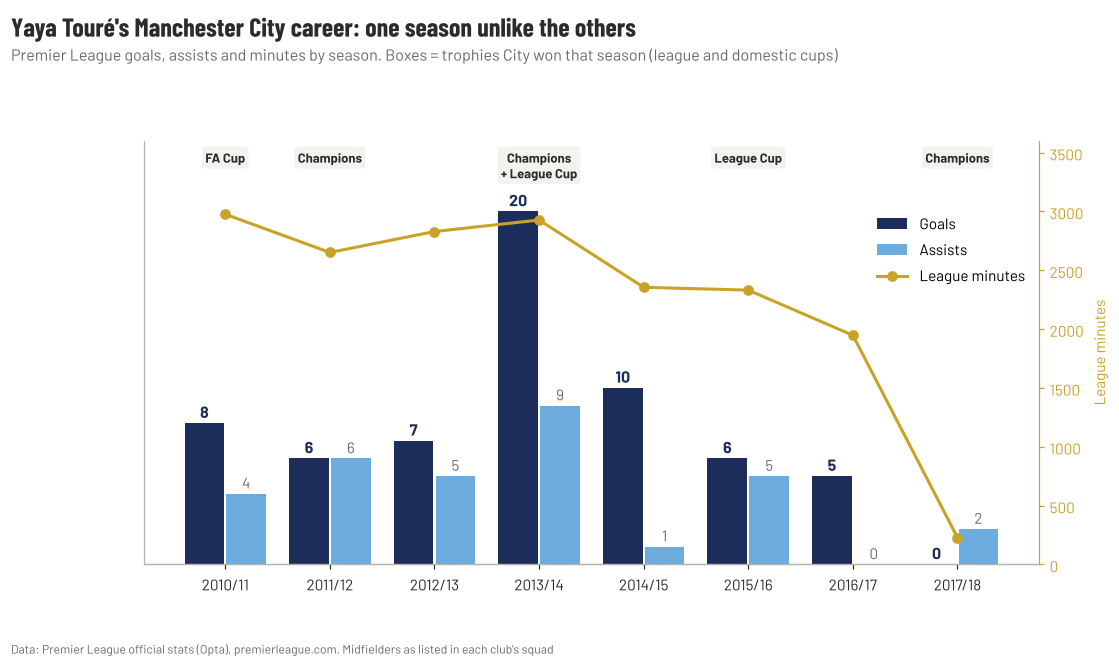

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 5))
x = np.arange(len(Y))
ax.bar(x - 0.2, Y.goals, width=0.38, color=NAVY, label="Goals")
ax.bar(x + 0.2, Y.goalAssists, width=0.38, color=SKY, label="Assists")
for xi, g, a in zip(x, Y.goals, Y.goalAssists):
    ax.text(xi - 0.2, g + 0.3, g, ha="center", fontsize=10.5, color=NAVY, fontweight="bold")
    ax.text(xi + 0.2, a + 0.3, a, ha="center", fontsize=10, color=MUTED)
ax2 = ax.twinx()
ax2.plot(x, Y.timePlayed, color=GOLD, lw=2, marker="o", label="League minutes")
ax2.set_ylim(0, 3600); ax2.set_ylabel("League minutes", color=GOLD); ax2.tick_params(axis="y", colors=GOLD)
ax2.spines["right"].set_visible(True); ax2.spines["right"].set_color(GOLD); ax2.spines["top"].set_visible(False)
honours = {2010: "FA Cup", 2011: "Champions", 2013: "Champions\n+ League Cup", 2015: "League Cup", 2017: "Champions"}
for xi, s in zip(x, Y.season):
    if s in honours:
        ax.text(xi, 23.5, honours[s], ha="center", va="top", fontsize=8.5, color=DARK, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc=LIGHT, ec="none"))
ax.set_xticks(x, [season_label(s) for s in Y.season]); ax.set_ylim(0, 24); ax.set_yticks([])
ax.spines["left"].set_visible(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right", bbox_to_anchor=(1, 0.86))
titles(fig, "Yaya Touré's Manchester City career: one season unlike the others",
       "Premier League goals, assists and minutes by season. Boxes = trophies City won that season (league and domestic cups)",
       SRC_PL)
fig.savefig(FIGS / "01_career_by_season.png")

## 2. 2013/14 among every midfield season of the era

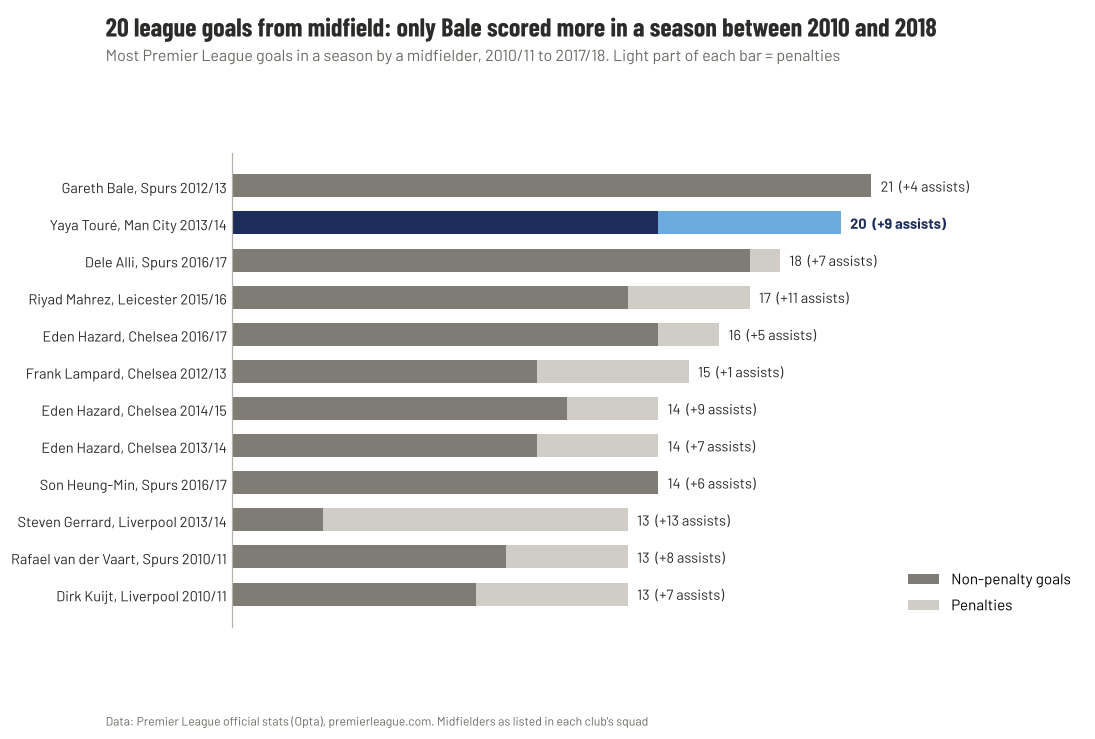

In [4]:
top = D.sort_values(["goals", "goalAssists"], ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
yy = np.arange(len(top))
is_y = top.name == YAYA
ax.barh(yy, top.npg, color=np.where(is_y, NAVY, "#7E7C75"), height=0.62, label="Non-penalty goals")
ax.barh(yy, top.penaltyGoals, left=top.npg, color=np.where(is_y, SKY, "#CFCDC6"), height=0.62, label="Penalties")
for yi, r in zip(yy, top.itertuples()):
    ax.text(r.goals + 0.3, yi, f"{r.goals}  (+{r.goalAssists} assists)", va="center", fontsize=9.5,
            color=NAVY if r.name == YAYA else DARK, fontweight="bold" if r.name == YAYA else "normal")
ax.set_yticks(yy, [f"{r.name}, {r.team} {season_label(r.season)}" for r in top.itertuples()], fontsize=9.5)
ax.set_xlim(0, top.goals.max() + 7); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")
titles(fig, "20 league goals from midfield: only Bale scored more in a season between 2010 and 2018",
       "Most Premier League goals in a season by a midfielder, 2010/11 to 2017/18. Light part of each bar = penalties",
       SRC_PL)
fig.savefig(FIGS / "02_top_midfield_goal_seasons.png")

## 3. A scorer and a passer at the same time

,season,name,team,npg,passes90
480,2012,Santiago Cazorla,Arsenal,12,67.2
640,2013,Yaya Touré,Man City,14,76.9
677,2013,David Silva,Man City,7,77.4
694,2013,Samir Nasri,Man City,7,68.4
842,2014,Yaya Touré,Man City,8,92.2
874,2014,David Silva,Man City,12,72.6
905,2014,Aaron Ramsey,Arsenal,6,73.5
954,2014,Ander Herrera,Man Utd,6,74.9
1280,2016,Mesut Özil,Arsenal,8,66.7
1464,2017,David Silva,Man City,9,89.8


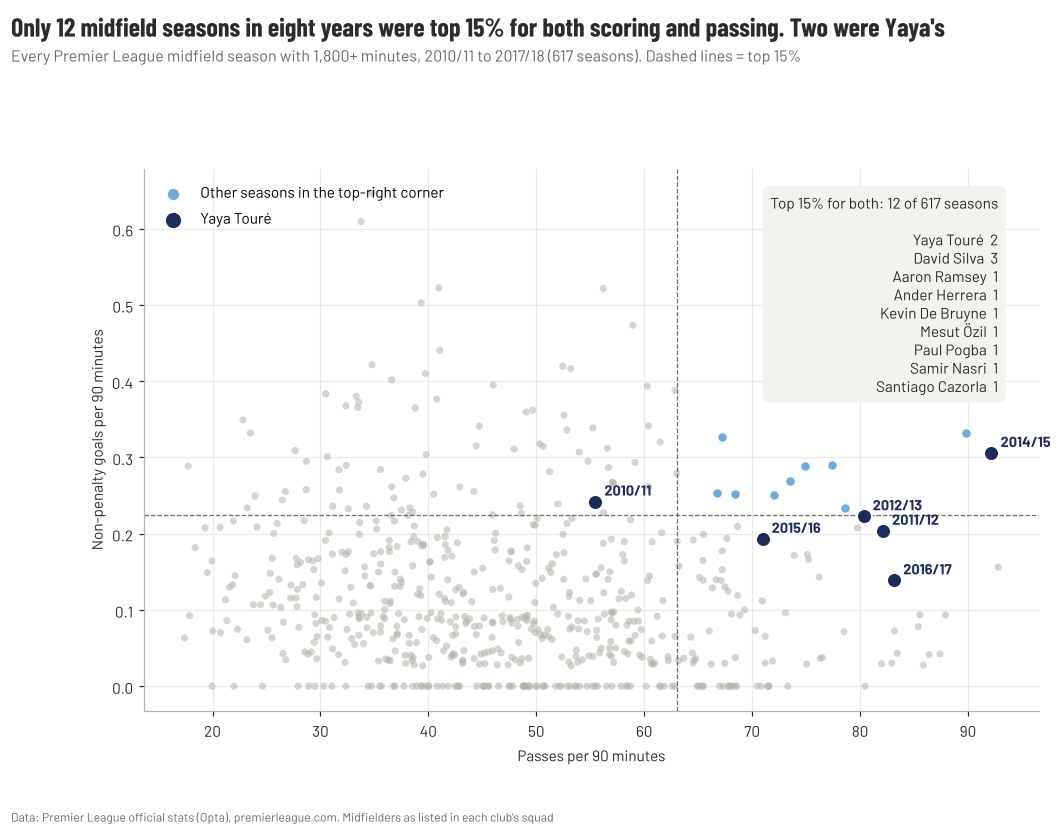

In [5]:
q_s, q_p = M.scoring.quantile(0.85), M.passes90.quantile(0.85)
corner = M[(M.scoring >= q_s) & (M.passes90 >= q_p)]
fig, ax = plt.subplots(figsize=(10.5, 6.4))
other = M[M.name != YAYA]
ax.scatter(other.passes90, other.scoring, s=22, color=GREY, alpha=0.55, edgecolors="none")
ax.axvline(q_p, color=MUTED, lw=0.8, ls="--"); ax.axhline(q_s, color=MUTED, lw=0.8, ls="--")
ym = M[M.name == YAYA]
ax.scatter(ym.passes90, ym.scoring, s=95, color=NAVY, edgecolors="white", lw=1.2, zorder=3)
ax.scatter([], [], s=40, color=SKY, label="Other seasons in the top-right corner"); ax.scatter([], [], s=80, color=NAVY, label="Yaya Touré")
ax.legend(frameon=False, loc="upper left")
for r in ym.itertuples():
    ax.annotate(season_label(r.season), (r.passes90, r.scoring), xytext=(6, 4), textcoords="offset points",
                fontsize=9.5, color=NAVY, fontweight="bold")
others = corner[corner.name != YAYA]
ax.scatter(others.passes90, others.scoring, s=40, color=SKY, edgecolors="white", lw=0.8, zorder=2)
names = others.groupby("name").season.count().sort_values(ascending=False)
ax.text(M.passes90.max(), M.scoring.max(), f"Top 15% for both: {len(corner)} of {len(M)} seasons\n\nYaya Touré  {(corner.name == YAYA).sum()}\n" +
        "\n".join(f"{n}  {c}" for n, c in names.items()),
        ha="right", va="top", fontsize=10, color=DARK, bbox=dict(boxstyle="round,pad=0.5", fc=LIGHT, ec="none"))
ax.set_xlabel("Passes per 90 minutes"); ax.set_ylabel("Non-penalty goals per 90 minutes")
ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True)
titles(fig, f"Only {len(corner)} midfield seasons in eight years were top 15% for both scoring and passing. Two were Yaya's",
       f"Every Premier League midfield season with 1,800+ minutes, 2010/11 to 2017/18 ({len(M)} seasons). Dashed lines = top 15%",
       SRC_PL)
fig.savefig(FIGS / "03_scorer_and_passer.png")
corner[["season", "name", "team", "npg", "passes90"]].round(1)

## 4. What kind of midfielder? The 2013/14 profile

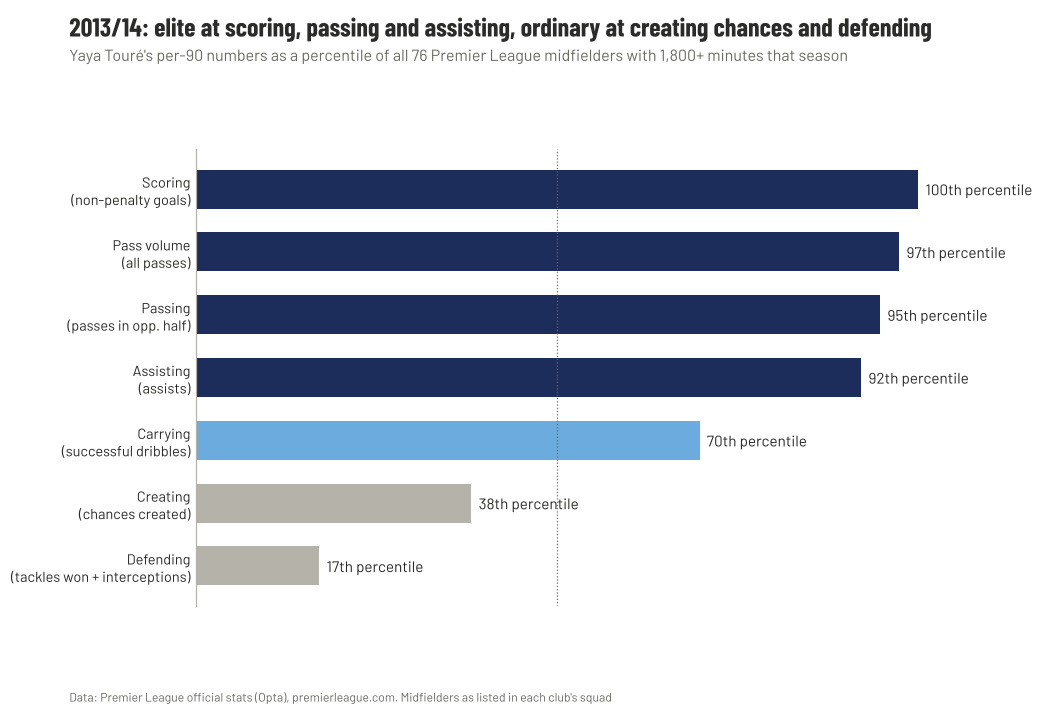

In [6]:
r13 = M[(M.name == YAYA) & (M.season == 2013)].iloc[0]
vals = [r13["p_" + c] for c in DIMS] + [r13.p_passes90]
labs = [DIM_LABELS[c] for c in DIMS] + ["Pass volume\n(all passes)"]
order = np.argsort(vals)
fig, ax = plt.subplots(figsize=(10, 5.4))
yy = np.arange(len(vals))
cols = [NAVY if vals[i] >= 0.8 else SKY if vals[i] >= 0.5 else GREY for i in order]
ax.barh(yy, [vals[i] for i in order], color=cols, height=0.62)
for yi, i in zip(yy, order):
    ax.text(vals[i] + 0.01, yi, f"{vals[i] * 100:.0f}th percentile", va="center", fontsize=10, color=DARK)
ax.set_yticks(yy, [labs[i] for i in order], fontsize=9.5)
ax.axvline(0.5, color=MUTED, lw=0.8, ls=":"); ax.set_xlim(0, 1.18); ax.set_xticks([])
ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
titles(fig, "2013/14: elite at scoring, passing and assisting, ordinary at creating chances and defending",
       "Yaya Touré's per-90 numbers as a percentile of all 76 Premier League midfielders with 1,800+ minutes that season",
       SRC_PL)
fig.savefig(FIGS / "04_profile_2013_14.png")

## 5. Goals vs expected goals (Opta xG, from 2012/13)

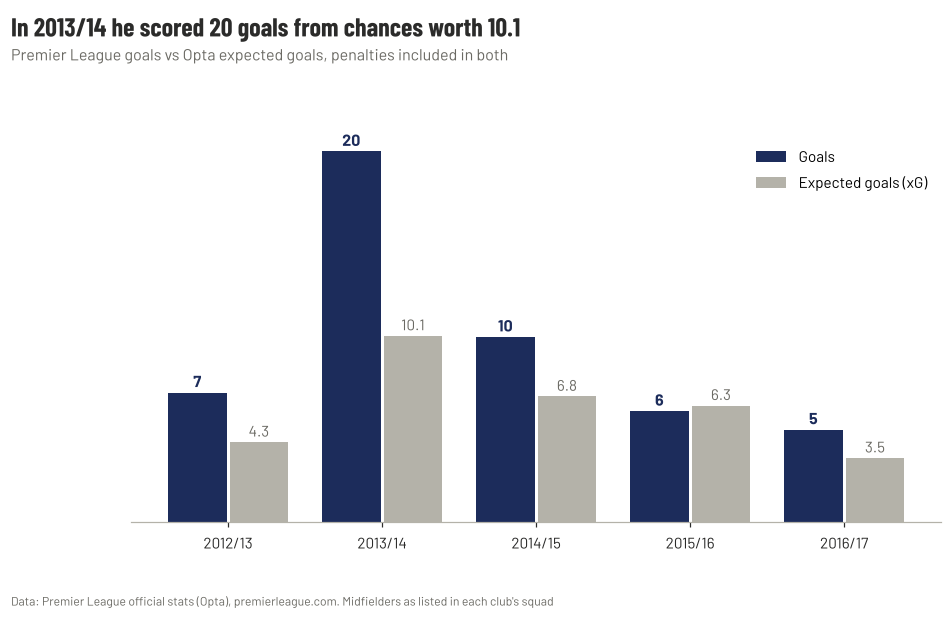

In [7]:
yx = Y[Y.season.between(2012, 2016)]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = np.arange(len(yx))
ax.bar(x - 0.2, yx.goals, width=0.38, color=NAVY, label="Goals")
ax.bar(x + 0.2, yx.expectedGoals, width=0.38, color=GREY, label="Expected goals (xG)")
for xi, g, e in zip(x, yx.goals, yx.expectedGoals):
    ax.text(xi - 0.2, g + 0.3, g, ha="center", fontsize=10.5, color=NAVY, fontweight="bold")
    ax.text(xi + 0.2, e + 0.3, f"{e:.1f}", ha="center", fontsize=10, color=MUTED)
ax.set_xticks(x, [season_label(s) for s in yx.season]); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.legend(frameon=False, loc="upper right")
r = yx[yx.season == 2013].iloc[0]
titles(fig, f"In 2013/14 he scored {r.goals} goals from chances worth {r.expectedGoals:.1f}",
       "Premier League goals vs Opta expected goals, penalties included in both",
       SRC_PL)
fig.savefig(FIGS / "05_goals_vs_xg.png")